In [1]:
import torch
# Fix CPU threading for a recorded, reproducible audit environment.
torch.set_num_threads(1)

In [2]:
import torch
import numpy as np
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.integrate import odeint
torch.manual_seed(0)
np.random.seed(0)

## Generate synthetic data that follows known disease rates

In [3]:
# We choose true disease rates
TRUE = {"beta": 0.50, "gamma":0.20, "omega": 1.0/14.0}

N_POP = 1_000_000.0  # total population

T_max = 160.0  # 160 days

I0 = 1/N_POP # one person infected at t=0

Y0 = [1-I0, I0, 0, 0]  # initial conditon [s, i, r, d ] at t=0

def sird_rhs(y, t, beta, gamma, omega):
    s, i, r, d = y
    return [-beta * s * i,
           beta * s * i - gamma * i - omega * i,
           gamma * i,
           omega * i]

def simulate(times, p):
    return odeint(sird_rhs, Y0, times, args = (p["beta"], p["gamma"], p["omega"]))

t_train = np.arange(0.0, T_max + 1e-9, 3.0)    # sparse: observation every 3 days
t_dense = np.arange(0.0, T_max + 1e-9, 1.0)     # dense grid for ploting
y_train = simulate(t_train, TRUE)          # Observed data
y_dense_true = simulate(t_dense, TRUE)         # ground truth for final ploting

We visualize the true curves

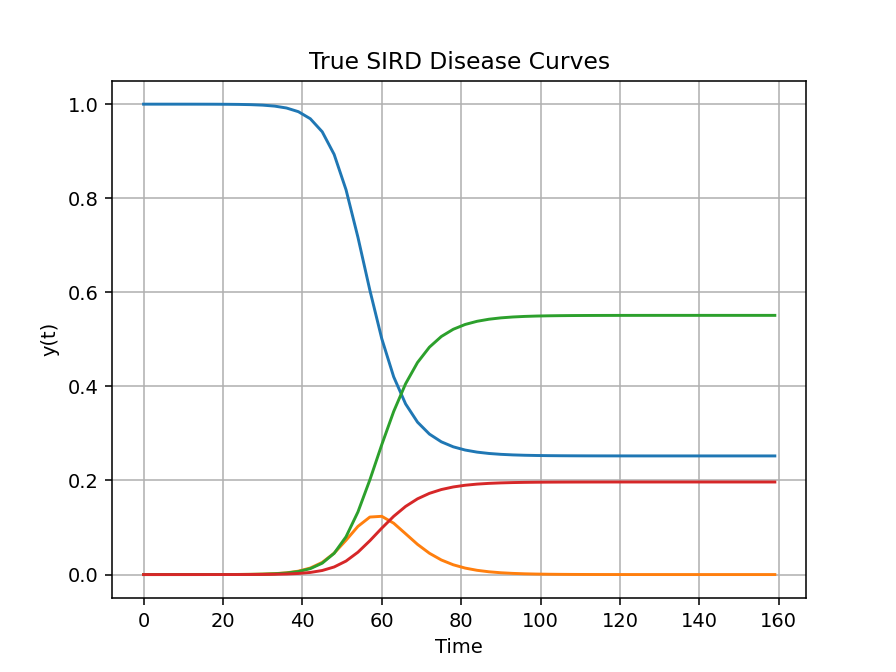

In [4]:
plt.plot(t_train, y_train)
plt.xlabel("Time")
plt.ylabel("y(t)")
plt.title("True SIRD Disease Curves")
plt.grid()
plt.show()

## Build a custom neural network for SIRD model

In [5]:
# This custom neural network model is designed to accept one input (time) and produce 4 outputs (s, i, r, d)

class MLP(nn.Module):
    def __init__(self, hidden =32, depth= 3):
        super().__init__()
        layers = [nn.Linear(1,hidden), nn.Tanh()]
        for i in range(depth-1):
            layers += [nn.Linear(hidden, hidden), nn.Tanh()]
        layers += [nn.Linear(hidden, 4)]
        self.net = nn.Sequential(*layers)

    def forward(self, tau):
        return self.net(tau)

model = MLP()

## Make unknown rates trainable

We start with a wrong parameter values and train them accordingly 

In [6]:
Guess = {"beta": 0.80, "gamma":0.10, "omega":0.15}

# Train the parameters
log_beta = nn.Parameter(torch.log(torch.tensor(Guess["beta"])))
log_gamma = nn.Parameter(torch.log(torch.tensor(Guess["gamma"])))
log_omega = nn.Parameter(torch.log(torch.tensor(Guess["omega"])))

def rates():
    return torch.exp(log_beta), torch.exp(log_gamma), torch.exp(log_omega)

## Build a customized loss function

In [7]:
# We start with the data loss
tau_train = torch.tensor(t_train/T_max, dtype = torch.float32).reshape(-1,1)
y_obs = torch.tensor(y_train, dtype=torch.float32)
mse = nn.MSELoss()
# loss_data = mse(model(tau_train), y_obs)

# Initial condition loss
tau0 = torch.zeros(1,1)
y0 = torch.tensor([Y0], dtype=torch.float32)
# loss_ic = mse(model(tau0), y0)

# Physics informed loss

tau_coll = torch.tensor(t_dense/T_max, dtype = torch.float32).reshape(-1,1)
tau_coll.requires_grad_(True)  # we will diff wrt to this input

def d_dtau(output, tau):  # d(output)d(input)
    return torch.autograd.grad(output, tau,
                               grad_outputs = torch.ones_like(output),
                               create_graph=True)[0]

def physics_residual():
    u = model(tau_coll)
    s,i,r,d = u[:, 0:1], u[:,1:2], u[:,2:3], u[:,3:4]
    beta, gamma, omega = rates()
    ds, di = d_dtau(s, tau_coll), d_dtau(i, tau_coll)
    dr, dd = d_dtau(r, tau_coll), d_dtau(d, tau_coll)
    
    rS = ds - T_max*(-beta*s*i)
    rI = di - T_max*(beta*s*i - gamma*i - omega*i)
    rR = dr - T_max*(gamma*i)
    rD = dd - T_max*(omega*i)
    return torch.cat([rS, rI, rR, rD], dim=1)
    



## Build Neural Network Training Loop

We define the weights

In [8]:
W_data, W_phy, W_ic = 1.0, 1e-4, 1.0
params = list(model.parameters()) + [log_beta, log_gamma, log_omega]
opt = torch.optim.Adam(params, lr= 1e-3)
iters = 20000

In [9]:
audit_history = []
for iter in range(iters+1):
    opt.zero_grad()  # clears last step's gradient
    loss_data = mse(model(tau_train), y_obs)
    loss_ic = mse(model(tau0,), y0)
    loss_phys = (physics_residual()**2).mean()
    loss = W_data*loss_data + W_phy*loss_phys + W_ic*loss_ic
    if iter % 100 == 0:
        audit_history.append([iter, float(loss_data.detach()), float(loss_phys.detach()),
            float(loss_ic.detach()), float(loss.detach()),
            *[float(x.detach()) for x in rates()]])
    loss.backward()
    opt.step()
    if iter % 2000 ==0:
        b, g, o = (float(x) for x in rates())
        print(f"iter {iter: 6d} | loss: {float(loss):.3e} | "
             f"beta: {b: .4f} | gamma: {g: .4f} | omega: {o: .4f}")

iter      0 | loss: 6.015e-01 | beta:  0.7992 | gamma:  0.0999 | omega:  0.1499
iter   2000 | loss: 5.388e-05 | beta:  0.4649 | gamma:  0.1900 | omega:  0.0733
iter   4000 | loss: 3.352e-06 | beta:  0.4948 | gamma:  0.1986 | omega:  0.0714
iter   6000 | loss: 1.649e-06 | beta:  0.4963 | gamma:  0.1987 | omega:  0.0718
iter   8000 | loss: 5.897e-07 | beta:  0.4991 | gamma:  0.1997 | omega:  0.0714
iter  10000 | loss: 2.975e-06 | beta:  0.4945 | gamma:  0.1986 | omega:  0.0713
iter  12000 | loss: 9.237e-07 | beta:  0.4999 | gamma:  0.1999 | omega:  0.0715
iter  14000 | loss: 2.887e-06 | beta:  0.5000 | gamma:  0.2000 | omega:  0.0715
iter  16000 | loss: 4.386e-06 | beta:  0.5002 | gamma:  0.2000 | omega:  0.0715
iter  18000 | loss: 1.323e-06 | beta:  0.4990 | gamma:  0.1996 | omega:  0.0713
iter  20000 | loss: 1.912e-07 | beta:  0.5002 | gamma:  0.2000 | omega:  0.0715


<notebook-cell-16>:15: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)


In [10]:
# We show recovered rates
b, g , o = (float(x) for x in rates() )
pred = {"beta": b, "gamma": g, "omega": o}
print(f"{'param':>6} | {'true': >8} | {'guess': >8} | {'recovered': >10} | {'rel. error':>8}")
for k in pred:
    rel = abs(pred[k]- TRUE[k])/ abs(TRUE[k])
    print(f"{k:>6} | {TRUE[k]:8.4f} | {Guess[k]:8.4f} | {pred[k]:10.4f} | {rel:8.4f}")

 param |     true |    guess |  recovered | rel. error
  beta |   0.5000 |   0.8000 |     0.5002 |   0.0003
 gamma |   0.2000 |   0.1000 |     0.2000 |   0.0001
 omega |   0.0714 |   0.1500 |     0.0715 |   0.0010


## Trajectory Plot

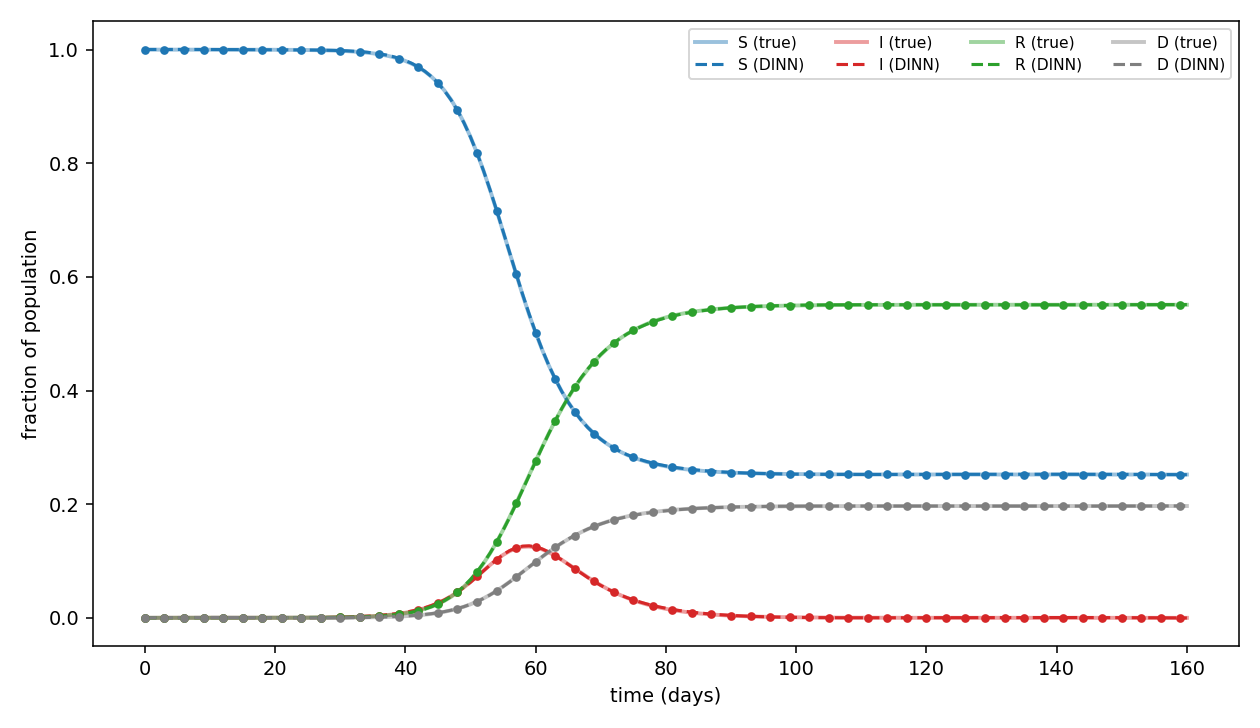

In [11]:
with torch.no_grad():
    tau_plot = torch.tensor(t_dense/T_max, dtype= torch.float32).reshape(-1,1)
    y_pred = model(tau_plot).numpy()

fig, ax = plt.subplots(figsize=(9, 5.2))
labels = ["S", "I", "R", "D"]; colors = ["#1f77b4", "#d62728", "#2ca02c", "#7f7f7f"]
for k in range(4):
    ax.plot(t_dense, y_dense_true[:, k], color=colors[k], lw=2, alpha=0.45,
    label=f"{labels[k]} (true)")
    ax.plot(t_dense, y_pred[:, k], color=colors[k], lw=1.6, ls="--",
    label=f"{labels[k]} (DINN)")
    ax.scatter(t_train, y_train[:, k], color=colors[k], s=12, zorder=3)
    
ax.set_xlabel("time (days)"); ax.set_ylabel("fraction of population")

ax.legend(ncol=4, fontsize=8); fig.tight_layout(); fig.savefig("pinndemic_fit.png",dpi=140)

## Step 1 reproduction audit

Diagnostics below use the same final trained model. They do not change the equations or training objective. Grid diagnostics are numerical checks, not proofs over continuous time.

{
  "utc_time": "2026-10-11T19:01:04.622380+00:00",
  "configuration": {
    "seed": 0,
    "device": "cpu",
    "dtype": "float32",
    "cpu_threads": 1,
    "hidden_width": 32,
    "hidden_layers": 3,
    "activation": "tanh",
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "optimizer_steps": 20001,
    "T_max_days": 160.0,
    "population": 1000000.0,
    "initial_state": [
      0.999999,
      1e-06,
      0,
      0
    ],
    "observations": 54,
    "first_observation_day": 0.0,
    "last_observation_day": 159.0,
    "observation_spacing_days": 3,
    "collocation_points": 161,
    "audit_grid_points": 641,
    "loss_weights": {
      "data": 1.0,
      "equations": 0.0001,
      "initial": 1.0
    }
  },
  "environment": {
    "python": "3.12.14",
    "torch": "2.14.1+cpu",
    "numpy": "2.3.5",
    "scipy": "1.17.0",
    "matplotlib": "3.10.8",
    "platform": "Linux-6.18.44-x86_64-with-glibc2.39"
  },
  "true_parameters": {
    "beta": 0.5,
    "gamma": 0.2,
    "ome

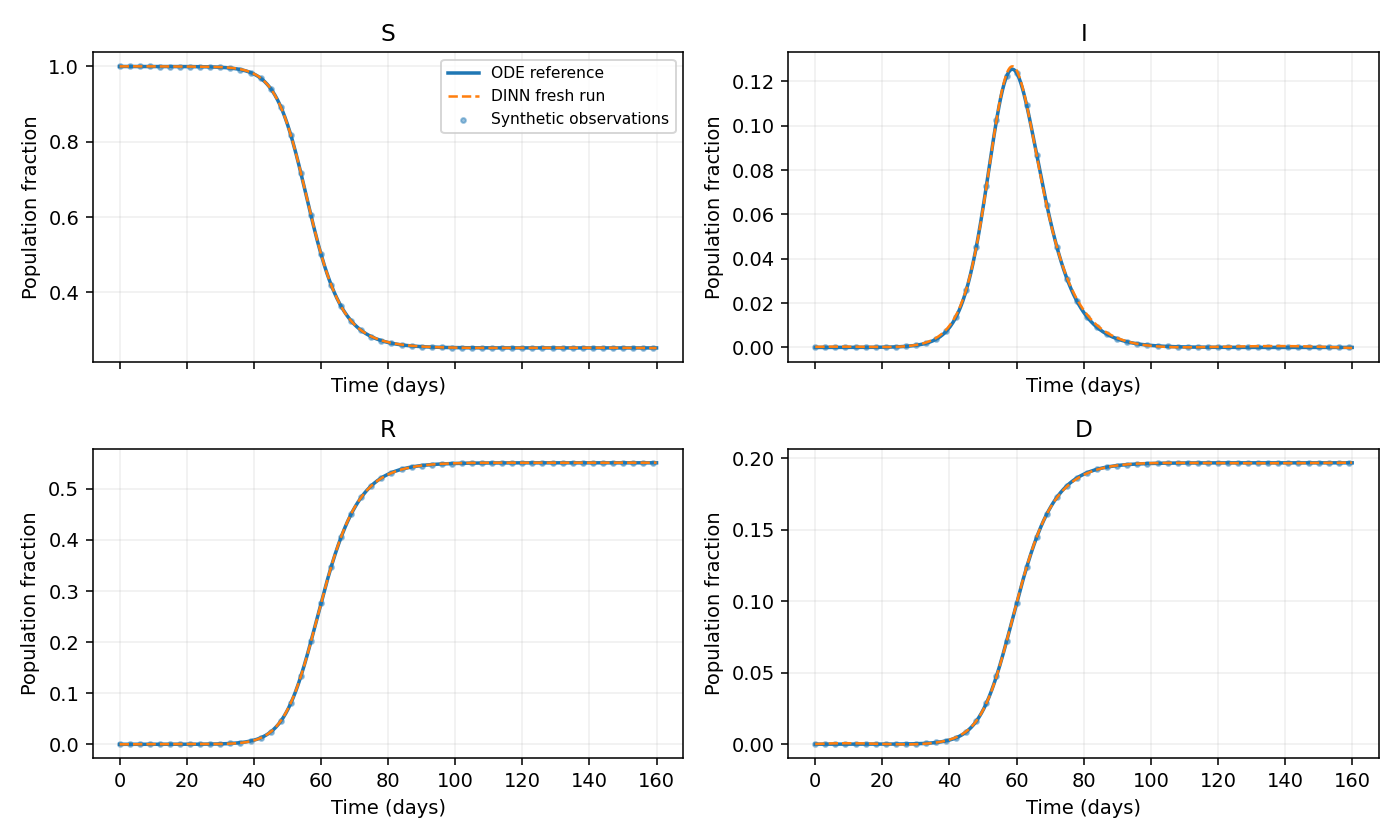

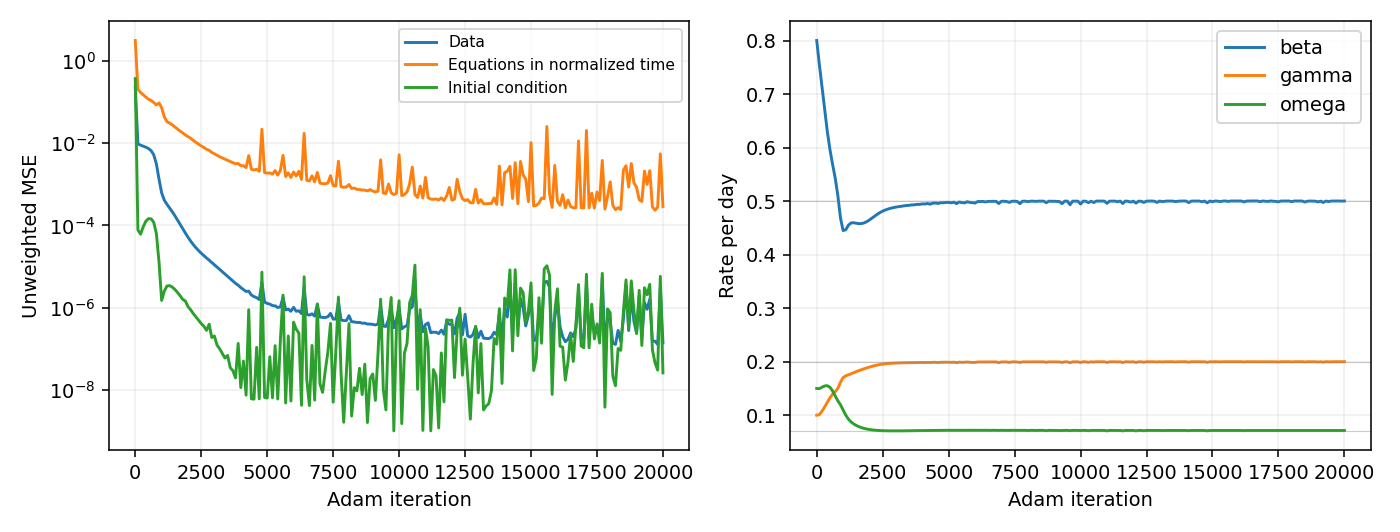

In [13]:

import csv, json, platform, sys
from pathlib import Path
from datetime import datetime, timezone
import scipy

audit_dir = Path('audit/repeat-results')
audit_dir.mkdir(parents=True, exist_ok=True)
audit_times = np.linspace(0.0, T_max, 641)
audit_tau = torch.tensor(audit_times/T_max, dtype=torch.float32).reshape(-1,1)
audit_tau.requires_grad_(True)
audit_u = model(audit_tau)
audit_s, audit_i, audit_r, audit_d = [audit_u[:, k:k+1] for k in range(4)]
audit_derivatives = torch.cat([d_dtau(v, audit_tau) for v in [audit_s,audit_i,audit_r,audit_d]],dim=1)/T_max
audit_b, audit_g, audit_o = rates()
audit_rhs = torch.cat([-audit_b*audit_s*audit_i,
    audit_b*audit_s*audit_i-(audit_g+audit_o)*audit_i,
    audit_g*audit_i, audit_o*audit_i],dim=1)
audit_res = (audit_derivatives-audit_rhs).detach().numpy()
audit_states = audit_u.detach().numpy()
audit_true = simulate(audit_times, TRUE)
audit_final = {k:float(v.detach()) for k,v in zip(['beta','gamma','omega'],rates())}
audit_rel = {k:abs(audit_final[k]-TRUE[k])/abs(TRUE[k]) for k in TRUE}
audit_grid_min = {k:float(audit_states[:,j].min()) for j,k in enumerate(['s','i','r','d'])}
audit_grid_max = {k:float(audit_states[:,j].max()) for j,k in enumerate(['s','i','r','d'])}
audit_final_losses = {
    'data_mse':float(mse(model(tau_train),y_obs).detach()),
    'initial_condition_mse':float(mse(model(tau0),y0).detach()),
    'equation_residual_mse_tau_training_grid':float((physics_residual()**2).mean().detach())}
audit_final_losses['weighted_total'] = W_data*audit_final_losses['data_mse']+W_ic*audit_final_losses['initial_condition_mse']+W_phy*audit_final_losses['equation_residual_mse_tau_training_grid']
audit_metrics = {
    'utc_time':datetime.now(timezone.utc).isoformat(),
    'configuration':{'seed':0,'device':'cpu','dtype':'float32','cpu_threads':torch.get_num_threads(),
        'hidden_width':32,'hidden_layers':3,'activation':'tanh','optimizer':'Adam',
        'learning_rate':1e-3,'optimizer_steps':iters+1,'T_max_days':T_max,
        'population':N_POP,'initial_state':Y0,'observations':len(t_train),
        'first_observation_day':float(t_train[0]),'last_observation_day':float(t_train[-1]),
        'observation_spacing_days':3,'collocation_points':len(t_dense),
        'audit_grid_points':len(audit_times),'loss_weights':{'data':W_data,'equations':W_phy,'initial':W_ic}},
    'environment':{'python':sys.version.split()[0],'torch':torch.__version__,
        'numpy':np.__version__,'scipy':scipy.__version__,'matplotlib':plt.matplotlib.__version__,
        'platform':platform.platform()},
    'true_parameters':TRUE,'initial_parameter_guesses':Guess,'recovered_parameters':audit_final,
    'relative_errors_fraction':audit_rel,'relative_errors_percent':{k:100*v for k,v in audit_rel.items()},
    'all_parameter_errors_below_0_1_percent':all(v<0.001 for v in audit_rel.values()),
    'final_losses':audit_final_losses,
    'trajectory_rmse_by_compartment':{k:float(np.sqrt(np.mean((audit_states[:,j]-audit_true[:,j])**2))) for j,k in enumerate(['s','i','r','d'])},
    'trajectory_rmse_overall':float(np.sqrt(np.mean((audit_states-audit_true)**2))),
    'equation_residual_rmse_per_day_by_compartment':{k:float(np.sqrt(np.mean(audit_res[:,j]**2))) for j,k in enumerate(['s','i','r','d'])},
    'equation_residual_max_abs_per_day':float(np.abs(audit_res).max()),
    'population_conservation_max_abs_error':float(np.max(np.abs(audit_states.sum(axis=1)-1))),
    'minimum_by_compartment':audit_grid_min,'maximum_by_compartment':audit_grid_max,
    'negative_entries':int(np.sum(audit_states<0)),
    'initial_condition_max_abs_error':float(np.max(np.abs(audit_states[0]-np.array(Y0)))),
    'independent_ode_grid_conservation_max_abs_error':float(np.max(np.abs(audit_true.sum(axis=1)-1))),
    'recovery_death_monotonicity_min_daily_derivative':{'r':float(audit_derivatives.detach().numpy()[:,2].min()),'d':float(audit_derivatives.detach().numpy()[:,3].min())}}

(audit_dir/'metrics.json').write_text(json.dumps(audit_metrics,indent=2))
with (audit_dir/'loss_history.csv').open('w',newline='') as f:
    w=csv.writer(f);w.writerow(['iteration','data_mse','equation_mse_tau','initial_mse','weighted_total','beta','gamma','omega']);w.writerows(audit_history)
with (audit_dir/'parameter_recovery.csv').open('w',newline='') as f:
    w=csv.writer(f);w.writerow(['parameter','true','initial_guess','recovered','relative_error_fraction','relative_error_percent'])
    for k in TRUE:w.writerow([k,TRUE[k],Guess[k],audit_final[k],audit_rel[k],100*audit_rel[k]])
with (audit_dir/'trajectory_audit.csv').open('w',newline='') as f:
    w=csv.writer(f);w.writerow(['day','s_true','i_true','r_true','d_true','s_dinn','i_dinn','r_dinn','d_dinn','s_residual_per_day','i_residual_per_day','r_residual_per_day','d_residual_per_day'])
    for j,t in enumerate(audit_times):w.writerow([t,*audit_true[j],*audit_states[j],*audit_res[j]])

fig,axs=plt.subplots(2,2,figsize=(10,6),sharex=True)
for j,(ax,k) in enumerate(zip(axs.ravel(),['S','I','R','D'])):
    ax.plot(audit_times,audit_true[:,j],label='ODE reference',lw=1.8)
    ax.plot(audit_times,audit_states[:,j],'--',label='DINN fresh run',lw=1.3)
    ax.scatter(t_train,y_train[:,j],s=6,alpha=.45,label='Synthetic observations')
    ax.set_title(k);ax.set_xlabel('Time (days)');ax.set_ylabel('Population fraction');ax.grid(alpha=.2)
axs[0,0].legend(fontsize=8);fig.tight_layout();fig.savefig(audit_dir/'trajectory_comparison.png',dpi=180);plt.show()
hist=np.asarray(audit_history)
fig,axs=plt.subplots(1,2,figsize=(10,3.8))
for j,k in [(1,'Data'),(2,'Equations in normalized time'),(3,'Initial condition')]:axs[0].semilogy(hist[:,0],np.maximum(hist[:,j],1e-20),label=k)
axs[0].set_xlabel('Adam iteration');axs[0].set_ylabel('Unweighted MSE');axs[0].legend(fontsize=8);axs[0].grid(alpha=.2)
for j,k in [(5,'beta'),(6,'gamma'),(7,'omega')]:axs[1].plot(hist[:,0],hist[:,j],label=k);axs[1].axhline(TRUE[k],lw=.6,alpha=.4,color='gray')
axs[1].set_xlabel('Adam iteration');axs[1].set_ylabel('Rate per day');axs[1].legend();axs[1].grid(alpha=.2)
fig.tight_layout();fig.savefig(audit_dir/'training_diagnostics.png',dpi=180);plt.show()
print(json.dumps(audit_metrics,indent=2))
